# Лабораторная работа 4. Методы градиента политики

**Исполнитель:** Баранов Вадим, вариант 2.  
**Уровень:** повышенный (hard).  
**Среда:** `CartPole-v1`, Gymnasium.

Работа оформлена в том же формате, что и предыдущие лабораторные: сначала фиксируются цель и формулы, затем приведён код, после него — графики, таблицы и ответы на обсуждения.

## 1. Цель и постановка задачи

Требуется программно сравнить четыре метода градиента политики на одной дискретной среде:

1. REINFORCE с полным Монте-Карло-возвратом;
2. REINFORCE с инженерной базовой линией $b$;
3. VPG с обучаемой функцией ценности $V(s)$ и энтропийным бонусом;
4. TRPO с ограничением среднего KL-расстояния.

Для сравнения зафиксированы архитектура политики `4–128–64–2`, пять зерен генератора `(12, 34, 56, 78, 90)`, целевой бюджет `30 000` шагов на зерно (обучение заканчивается на границе эпизода: от 30 000 до 30 403 шагов) и детерминированная оценка на 30 эпизодах. Основные показатели — средняя награда, стандартное отклонение и доля эпизодов с результатом не ниже 475.

## 2. Теоретическая часть

Политика задаёт распределение $\pi_\theta(a\mid s)$. Для REINFORCE обновление параметров имеет вид

$$\nabla_\theta J(\theta)=\mathbb{E}\left[\sum_t \nabla_\theta\log\pi_\theta(A_t\mid S_t)G_t\right],$$

где $G_t=\sum_{k=t}^{T-1}\gamma^{k-t}R_k$ — дисконтированный возврат от шага $t$.

Базовая линия не меняет математическое ожидание градиента, если не зависит от выбранного действия:

$$\nabla_\theta J(\theta)=\mathbb{E}\left[\sum_t \nabla_\theta\log\pi_\theta(A_t\mid S_t)(G_t-b)\right].$$

В VPG базовая линия аппроксимируется отдельной сетью $V_\phi(s)$, а функция преимущества вычисляется как $A_t=G_t-V_\phi(S_t)$. Энтропийный член $\beta H(\pi_\theta)$ поддерживает исследование в начале обучения.

TRPO оптимизирует отношение вероятностей старой и новой политики

$$L(\theta)=\mathbb{E}_t\left[\frac{\pi_\theta(A_t\mid S_t)}{\pi_{\theta_{old}}(A_t\mid S_t)}A_t\right]$$

при ограничении $\overline{D}_{KL}(\pi_{\theta_{old}}\,\|\,\pi_\theta)\leq\delta$. Направление шага находится методом сопряжённых градиентов, а длина проверяется линейным поиском.

## 3. Среда и критерии

В `CartPole-v1` наблюдение содержит четыре числа: положение тележки, её скорость, угол стержня и угловую скорость. Доступны два действия — толчок влево и вправо. Эпизод заканчивается при падении стержня, выходе тележки за границу или достижении лимита 500 шагов.

Для каждого метода и каждого зерна сохраняются кривые обучения, средняя оценка, разброс, энтропия политики и значения функции потерь. В итоговой оценке действие выбирается жадно по логитам политики.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("fivethirtyeight")
plt.rcParams.update({
    "figure.figsize": (14, 7),
    "font.size": 13,
    "axes.titlesize": 17,
    "axes.labelsize": 14,
    "legend.fontsize": 11,
})

PROJECT_DIR = Path.cwd()
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SEEDS = (12, 34, 56, 78, 90)
TOTAL_STEPS = 30000
EVAL_EVERY = 2048

## 4. Реализация алгоритмов

Ниже приведён полный код четырёх агентов. Вызовы среды используют интерфейс Gymnasium с отдельными флагами `terminated` и `truncated`; возвраты для TRPO считаются внутри каждого эпизода, поэтому соседние траектории не смешиваются.

In [2]:
from __future__ import annotations

import json
import math
import random
import time
from dataclasses import dataclass
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical


torch.set_num_threads(1)
DEVICE = torch.device("cpu")
ENV_ID = "CartPole-v1"
SEEDS = (12, 34, 56, 78, 90)
TOTAL_STEPS = 30000
EVAL_EVERY = 2048


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


class PolicyNet(nn.Module):
    def __init__(self, obs_dim: int, action_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 64),
            nn.Tanh(),
            nn.Linear(64, action_dim),
        )

    def forward(self, states: torch.Tensor) -> torch.Tensor:
        return self.net(states)


class ValueNet(nn.Module):
    def __init__(self, obs_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 64),
            nn.Tanh(),
            nn.Linear(64, 1),
        )

    def forward(self, states: torch.Tensor) -> torch.Tensor:
        return self.net(states).squeeze(-1)


def discounted_returns(rewards: list[float], gamma: float) -> np.ndarray:
    out = np.zeros(len(rewards), dtype=np.float32)
    running = 0.0
    for i in range(len(rewards) - 1, -1, -1):
        running = rewards[i] + gamma * running
        out[i] = running
    return out


@dataclass
class Episode:
    states: list[np.ndarray]
    actions: list[int]
    rewards: list[float]
    log_probs: list[torch.Tensor]
    entropies: list[torch.Tensor]


def collect_episode(
    env: gym.Env,
    policy: PolicyNet,
    max_episode_steps: int = 500,
) -> Episode:
    state, _ = env.reset()
    states: list[np.ndarray] = []
    actions: list[int] = []
    rewards: list[float] = []
    log_probs: list[torch.Tensor] = []
    entropies: list[torch.Tensor] = []

    for _ in range(max_episode_steps):
        state_tensor = torch.as_tensor(state, dtype=torch.float32, device=DEVICE)
        distribution = Categorical(logits=policy(state_tensor))
        action_tensor = distribution.sample()
        next_state, reward, terminated, truncated, _ = env.step(int(action_tensor.item()))
        states.append(np.asarray(state, dtype=np.float32))
        actions.append(int(action_tensor.item()))
        rewards.append(float(reward))
        log_probs.append(distribution.log_prob(action_tensor))
        entropies.append(distribution.entropy())
        state = next_state
        if terminated or truncated:
            break

    return Episode(states, actions, rewards, log_probs, entropies)


def evaluate_policy(policy: PolicyNet, seed: int, episodes: int = 10) -> tuple[float, float, float]:
    env = gym.make(ENV_ID)
    scores: list[float] = []
    for episode_idx in range(episodes):
        state, _ = env.reset(seed=seed + 10000 + episode_idx)
        score = 0.0
        for _ in range(500):
            with torch.no_grad():
                action = int(torch.argmax(policy(torch.as_tensor(state, dtype=torch.float32))).item())
            state, reward, terminated, truncated, _ = env.step(action)
            score += float(reward)
            if terminated or truncated:
                break
        scores.append(score)
    env.close()
    scores_array = np.asarray(scores, dtype=np.float32)
    return float(scores_array.mean()), float(scores_array.std()), float(np.mean(scores_array >= 475.0))


def add_checkpoint(
    history: dict[str, list[float]],
    policy: PolicyNet,
    seed: int,
    total_steps: int,
    next_checkpoint: int,
) -> int:
    if total_steps >= next_checkpoint:
        score, score_std, success_rate = evaluate_policy(policy, seed)
        history["eval_steps"].append(float(total_steps))
        history["eval_mean"].append(score)
        history["eval_std"].append(score_std)
        history["success_rate"].append(success_rate)
        return next_checkpoint + EVAL_EVERY
    return next_checkpoint


def train_reinforce(seed: int, total_steps: int = TOTAL_STEPS) -> dict:
    set_seed(seed)
    env = gym.make(ENV_ID)
    env.reset(seed=seed)
    env.action_space.seed(seed)
    policy = PolicyNet(env.observation_space.shape[0], env.action_space.n).to(DEVICE)
    optimizer = torch.optim.Adam(policy.parameters(), lr=8e-4)
    history = {"train_steps": [], "train_score": [], "loss": [], "entropy": [], "eval_steps": [], "eval_mean": [], "eval_std": [], "success_rate": []}
    steps = 0
    next_checkpoint = EVAL_EVERY
    while steps < total_steps:
        episode = collect_episode(env, policy)
        returns = torch.as_tensor(discounted_returns(episode.rewards, 0.99), dtype=torch.float32)
        log_probs = torch.stack(episode.log_probs)
        entropy = torch.stack(episode.entropies).mean()
        loss = -(log_probs * returns).mean()
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
        optimizer.step()
        steps += len(episode.rewards)
        history["train_steps"].append(float(steps))
        history["train_score"].append(float(sum(episode.rewards)))
        history["loss"].append(float(loss.detach()))
        history["entropy"].append(float(entropy.detach()))
        next_checkpoint = add_checkpoint(history, policy, seed, steps, next_checkpoint)
    if not history["eval_steps"] or history["eval_steps"][-1] < steps:
        score, score_std, success_rate = evaluate_policy(policy, seed)
        history["eval_steps"].append(float(steps))
        history["eval_mean"].append(score)
        history["eval_std"].append(score_std)
        history["success_rate"].append(success_rate)
    env.close()
    history["final_score"], history["final_std"], history["final_success"] = evaluate_policy(policy, seed, episodes=30)
    return history


def train_reinforce_baseline(seed: int, total_steps: int = TOTAL_STEPS) -> dict:
    set_seed(seed)
    env = gym.make(ENV_ID)
    env.reset(seed=seed)
    env.action_space.seed(seed)
    policy = PolicyNet(env.observation_space.shape[0], env.action_space.n).to(DEVICE)
    optimizer = torch.optim.Adam(policy.parameters(), lr=8e-4)
    history = {"train_steps": [], "train_score": [], "loss": [], "entropy": [], "baseline": [], "eval_steps": [], "eval_mean": [], "eval_std": [], "success_rate": []}
    steps = 0
    next_checkpoint = EVAL_EVERY
    while steps < total_steps:
        episode = collect_episode(env, policy)
        returns_np = discounted_returns(episode.rewards, 0.99)
        returns = torch.as_tensor(returns_np, dtype=torch.float32)
        baseline = returns.mean().detach()
        advantages = returns - baseline
        log_probs = torch.stack(episode.log_probs)
        entropy = torch.stack(episode.entropies).mean()
        loss = -(log_probs * advantages).mean()
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
        optimizer.step()
        steps += len(episode.rewards)
        history["train_steps"].append(float(steps))
        history["train_score"].append(float(sum(episode.rewards)))
        history["loss"].append(float(loss.detach()))
        history["entropy"].append(float(entropy.detach()))
        history["baseline"].append(float(baseline))
        next_checkpoint = add_checkpoint(history, policy, seed, steps, next_checkpoint)
    if not history["eval_steps"] or history["eval_steps"][-1] < steps:
        score, score_std, success_rate = evaluate_policy(policy, seed)
        history["eval_steps"].append(float(steps))
        history["eval_mean"].append(score)
        history["eval_std"].append(score_std)
        history["success_rate"].append(success_rate)
    env.close()
    history["final_score"], history["final_std"], history["final_success"] = evaluate_policy(policy, seed, episodes=30)
    return history


def train_vpg(seed: int, total_steps: int = TOTAL_STEPS) -> dict:
    set_seed(seed)
    env = gym.make(ENV_ID)
    env.reset(seed=seed)
    env.action_space.seed(seed)
    policy = PolicyNet(env.observation_space.shape[0], env.action_space.n).to(DEVICE)
    value = ValueNet(env.observation_space.shape[0]).to(DEVICE)
    policy_optimizer = torch.optim.Adam(policy.parameters(), lr=6e-4)
    value_optimizer = torch.optim.Adam(value.parameters(), lr=1e-3)
    history = {"train_steps": [], "train_score": [], "policy_loss": [], "value_loss": [], "entropy": [], "eval_steps": [], "eval_mean": [], "eval_std": [], "success_rate": []}
    steps = 0
    next_checkpoint = EVAL_EVERY
    while steps < total_steps:
        episode = collect_episode(env, policy)
        states = torch.as_tensor(np.asarray(episode.states), dtype=torch.float32)
        returns = torch.as_tensor(discounted_returns(episode.rewards, 0.99), dtype=torch.float32)
        values = value(states)
        advantages = returns - values.detach()
        advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)
        actions = torch.as_tensor(episode.actions, dtype=torch.long)
        distribution = Categorical(logits=policy(states))
        log_probs = distribution.log_prob(actions)
        entropy = distribution.entropy().mean()
        policy_loss = -(log_probs * advantages).mean() - 0.01 * entropy
        value_loss = F.mse_loss(values, returns)
        policy_optimizer.zero_grad()
        policy_loss.backward()
        torch.nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
        policy_optimizer.step()
        value_optimizer.zero_grad()
        value_loss.backward()
        torch.nn.utils.clip_grad_norm_(value.parameters(), 1.0)
        value_optimizer.step()
        steps += len(episode.rewards)
        history["train_steps"].append(float(steps))
        history["train_score"].append(float(sum(episode.rewards)))
        history["policy_loss"].append(float(policy_loss.detach()))
        history["value_loss"].append(float(value_loss.detach()))
        history["entropy"].append(float(entropy.detach()))
        next_checkpoint = add_checkpoint(history, policy, seed, steps, next_checkpoint)
    if not history["eval_steps"] or history["eval_steps"][-1] < steps:
        score, score_std, success_rate = evaluate_policy(policy, seed)
        history["eval_steps"].append(float(steps))
        history["eval_mean"].append(score)
        history["eval_std"].append(score_std)
        history["success_rate"].append(success_rate)
    env.close()
    history["final_score"], history["final_std"], history["final_success"] = evaluate_policy(policy, seed, episodes=30)
    return history


def flat_params(model: nn.Module) -> torch.Tensor:
    return torch.cat([p.detach().reshape(-1) for p in model.parameters()])


def flat_grad(grads: tuple[torch.Tensor | None, ...], model: nn.Module) -> torch.Tensor:
    pieces = []
    for param, grad in zip(model.parameters(), grads):
        pieces.append(torch.zeros_like(param).reshape(-1) if grad is None else grad.reshape(-1))
    return torch.cat(pieces)


def set_flat_params(model: nn.Module, vector: torch.Tensor) -> None:
    offset = 0
    for param in model.parameters():
        size = param.numel()
        param.data.copy_(vector[offset:offset + size].view_as(param))
        offset += size


def conjugate_gradients(fvp, b: torch.Tensor, iterations: int = 10) -> torch.Tensor:
    x = torch.zeros_like(b)
    r = b.clone()
    p = b.clone()
    rdotr = torch.dot(r, r)
    for _ in range(iterations):
        z = fvp(p)
        alpha = rdotr / (torch.dot(p, z) + 1e-8)
        x = x + alpha * p
        r = r - alpha * z
        new_rdotr = torch.dot(r, r)
        if float(new_rdotr) < 1e-10:
            break
        p = r + (new_rdotr / (rdotr + 1e-8)) * p
        rdotr = new_rdotr
    return x


def train_trpo(seed: int, total_steps: int = TOTAL_STEPS, batch_steps: int = 2048) -> dict:
    set_seed(seed)
    env = gym.make(ENV_ID)
    env.reset(seed=seed)
    env.action_space.seed(seed)
    policy = PolicyNet(env.observation_space.shape[0], env.action_space.n).to(DEVICE)
    value = ValueNet(env.observation_space.shape[0]).to(DEVICE)
    value_optimizer = torch.optim.Adam(value.parameters(), lr=1e-3)
    history = {"train_steps": [], "train_score": [], "policy_loss": [], "value_loss": [], "kl": [], "accepted_fraction": [], "eval_steps": [], "eval_mean": [], "eval_std": [], "success_rate": []}
    steps = 0
    while steps < total_steps:
        states_list: list[np.ndarray] = []
        actions_list: list[int] = []
        returns_list: list[float] = []
        episode_scores: list[float] = []
        collected_steps = 0
        while collected_steps < batch_steps and steps + collected_steps < total_steps:
            episode = collect_episode(env, policy)
            episode_returns = discounted_returns(episode.rewards, 0.99)
            states_list.extend(episode.states)
            actions_list.extend(episode.actions)
            returns_list.extend(episode_returns.tolist())
            episode_scores.append(float(sum(episode.rewards)))
            collected_steps += len(episode.rewards)
        steps += collected_steps
        states = torch.as_tensor(np.asarray(states_list), dtype=torch.float32)
        actions = torch.as_tensor(np.asarray(actions_list), dtype=torch.long)
        returns = torch.as_tensor(np.asarray(returns_list), dtype=torch.float32)
        with torch.no_grad():
            old_logits = policy(states)
            old_distribution = Categorical(logits=old_logits)
            old_log_probs = old_distribution.log_prob(actions)
            old_probs = old_distribution.probs.detach()
            old_values = value(states)
            advantages = returns - old_values
            advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

        def surrogate() -> torch.Tensor:
            distribution = Categorical(logits=policy(states))
            ratio = torch.exp(distribution.log_prob(actions) - old_log_probs)
            return (ratio * advantages).mean()

        def mean_kl() -> torch.Tensor:
            distribution = Categorical(logits=policy(states))
            return (old_probs * (torch.log(old_probs + 1e-8) - torch.log(distribution.probs + 1e-8))).sum(dim=1).mean()

        objective = surrogate()
        policy_grads = torch.autograd.grad(objective, policy.parameters())
        gradient = flat_grad(policy_grads, policy).detach()
        kl_grads = torch.autograd.grad(mean_kl(), policy.parameters(), create_graph=True)
        flat_kl_grad = flat_grad(kl_grads, policy)

        def fvp(vector: torch.Tensor) -> torch.Tensor:
            kl_vector = (flat_kl_grad * vector).sum()
            second_grads = torch.autograd.grad(kl_vector, policy.parameters(), retain_graph=True)
            return flat_grad(second_grads, policy).detach() + 0.1 * vector

        direction = conjugate_gradients(fvp, gradient)
        curvature = torch.dot(direction, fvp(direction))
        scale = torch.sqrt(torch.tensor(0.01) / (0.5 * curvature + 1e-8))
        full_step = direction * scale
        old_vector = flat_params(policy)
        old_objective = float(objective.detach())
        accepted_fraction = 0.0
        accepted_kl = 0.0
        for fraction in (1.0, 0.5, 0.25, 0.125, 0.0625, 0.03125, 0.0):
            set_flat_params(policy, old_vector + fraction * full_step)
            new_objective = float(surrogate().detach())
            kl_value = float(mean_kl().detach())
            if fraction == 0.0 or (math.isfinite(new_objective) and new_objective > old_objective and kl_value <= 0.01):
                accepted_fraction = fraction
                accepted_kl = kl_value
                break
        if accepted_fraction == 0.0:
            set_flat_params(policy, old_vector)
            accepted_kl = 0.0

        for _ in range(5):
            value_loss = F.mse_loss(value(states), returns)
            value_optimizer.zero_grad()
            value_loss.backward()
            torch.nn.utils.clip_grad_norm_(value.parameters(), 1.0)
            value_optimizer.step()

        history["train_steps"].append(float(steps))
        history["train_score"].append(float(np.mean(episode_scores)))
        history["policy_loss"].append(float(-surrogate().detach()))
        history["value_loss"].append(float(value_loss.detach()))
        history["kl"].append(float(accepted_kl))
        history["accepted_fraction"].append(float(accepted_fraction))
        score, score_std, success_rate = evaluate_policy(policy, seed)
        history["eval_steps"].append(float(steps))
        history["eval_mean"].append(score)
        history["eval_std"].append(score_std)
        history["success_rate"].append(success_rate)
    env.close()
    history["final_score"], history["final_std"], history["final_success"] = evaluate_policy(policy, seed, episodes=30)
    return history


def run_all(seeds: tuple[int, ...] = SEEDS, total_steps: int = TOTAL_STEPS) -> dict:
    runners = {
        "REINFORCE": train_reinforce,
        "REINFORCE + baseline": train_reinforce_baseline,
        "VPG": train_vpg,
        "TRPO": train_trpo,
    }
    result: dict[str, dict[str, dict]] = {}
    for name, runner in runners.items():
        result[name] = {}
        for seed in seeds:
            started = time.perf_counter()
            result[name][str(seed)] = runner(seed, total_steps)
            result[name][str(seed)]["wall_time"] = time.perf_counter() - started
            print(f"{name:24s} seed={seed}: score={result[name][str(seed)]['final_score']:.1f} time={result[name][str(seed)]['wall_time']:.1f}s")
    return result


def to_jsonable(value):
    if isinstance(value, dict):
        return {str(k): to_jsonable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_jsonable(v) for v in value]
    if isinstance(value, (np.floating, np.integer)):
        return value.item()
    return value


if False:
    results = run_all()
    Path("results").mkdir(exist_ok=True)
    Path("results/metrics.json").write_text(json.dumps(to_jsonable(results), ensure_ascii=False, indent=2), encoding="utf-8")
    print("saved results/metrics.json")

## 5. Контрольный запуск

Обучение выполнено на компьютере с Python 3.12, PyTorch 2.11.0+cpu, NumPy 2.2.4, Matplotlib 3.10.8 и Gymnasium 1.3.0. Метрики сохранены в `results/metrics.json`; повторный расчёт можно включить параметром `RUN_EXPERIMENTS=True`. При обычном открытии ноутбука загружается сохранённый набор, чтобы графики строились сразу.

In [3]:
RUN_EXPERIMENTS = False
if RUN_EXPERIMENTS:
    results = run_all(seeds=SEEDS, total_steps=TOTAL_STEPS)
    RESULTS_DIR.mkdir(exist_ok=True)
    (RESULTS_DIR / "metrics.json").write_text(json.dumps(to_jsonable(results), ensure_ascii=False, indent=2), encoding="utf-8")
else:
    results = json.loads((RESULTS_DIR / "metrics.json").read_text(encoding="utf-8"))

summary_rows = []
for method, runs in results.items():
    scores = np.array([run["final_score"] for run in runs.values()], dtype=float)
    success = np.array([run["final_success"] for run in runs.values()], dtype=float)
    summary_rows.append({
        "Метод": method,
        "Средняя награда": scores.mean(),
        "Стандартное отклонение": scores.std(ddof=1),
        "Доля успешных эпизодов": success.mean(),
        "Лучшее зерно": list(runs.keys())[int(np.argmax(scores))],
    })
summary = pd.DataFrame(summary_rows).sort_values("Средняя награда", ascending=False).reset_index(drop=True)
display(summary.style.format({"Средняя награда": "{:.1f}", "Стандартное отклонение": "{:.1f}", "Доля успешных эпизодов": "{:.1%}"}))

,Метод,Средняя награда,Стандартное отклонение,Доля успешных эпизодов,Лучшее зерно
0,TRPO,481.3,20.6,87.3%,78
1,VPG,464.2,24.9,71.3%,78
2,REINFORCE + baseline,307.2,152.7,27.3%,12
3,REINFORCE,108.3,58.2,0.0%,12


По итоговой таблице лучшую среднюю оценку получил TRPO (481.3 ± 20.6), а VPG дал 464.2 ± 24.9. Разброс по зернам показывает изменчивость результата между запусками.

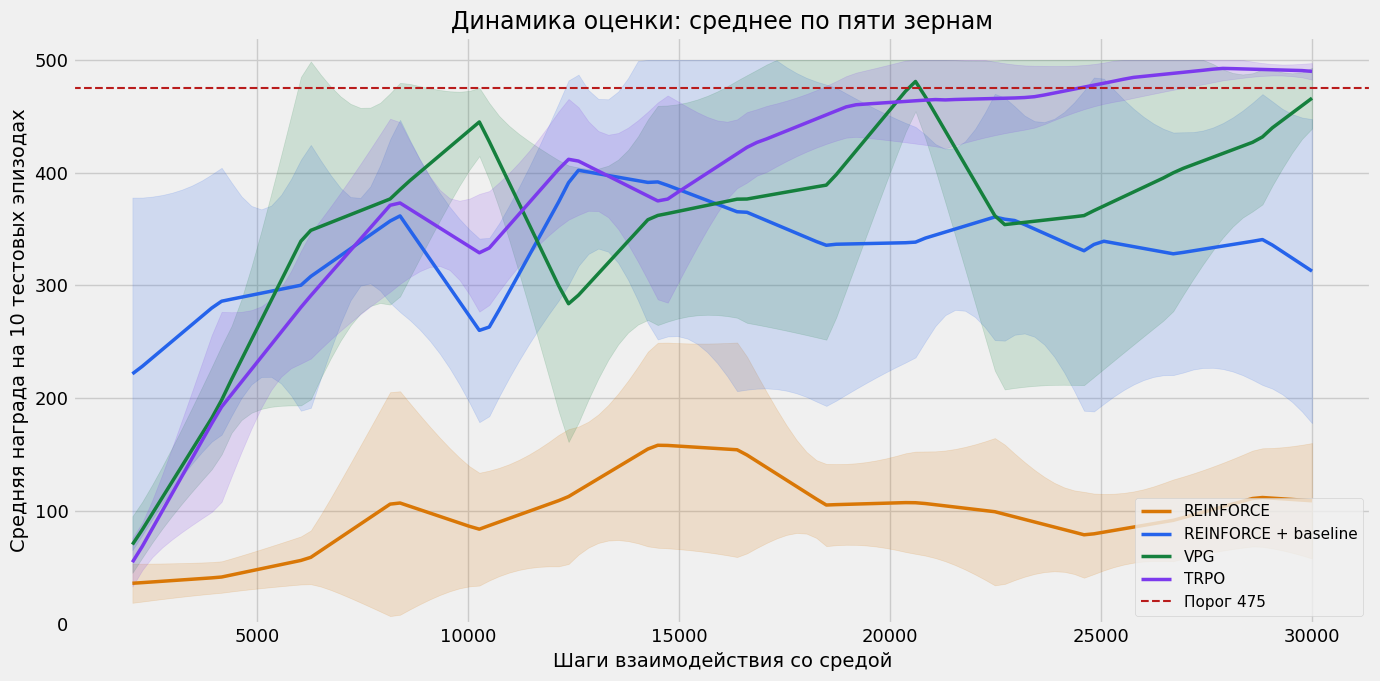

In [4]:
def interpolated_curves(method, grid):
    curves = []
    for run in results[method].values():
        x = np.asarray(run["eval_steps"], dtype=float)
        y = np.asarray(run["eval_mean"], dtype=float)
        curves.append(np.interp(grid, x, y))
    matrix = np.asarray(curves)
    return matrix.mean(axis=0), matrix.std(axis=0)

grid = np.linspace(EVAL_EVERY, TOTAL_STEPS, 120)
colors = {"REINFORCE": "#d97706", "REINFORCE + baseline": "#2563eb", "VPG": "#15803d", "TRPO": "#7c3aed"}
fig, ax = plt.subplots(figsize=(14, 7))
for method, color in colors.items():
    mean_curve, std_curve = interpolated_curves(method, grid)
    ax.plot(grid, mean_curve, color=color, linewidth=2.5, label=method)
    ax.fill_between(grid, np.maximum(0, mean_curve - std_curve), np.minimum(500, mean_curve + std_curve), color=color, alpha=0.16)
ax.axhline(475, color="#b91c1c", linestyle="--", linewidth=1.5, label="Порог 475")
ax.set_title("Динамика оценки: среднее по пяти зернам")
ax.set_xlabel("Шаги взаимодействия со средой")
ax.set_ylabel("Средняя награда на 10 тестовых эпизодах")
ax.set_ylim(0, 520)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "learning_curves.png", dpi=220)
plt.show()

На кривых видно различие между методами. Чистый REINFORCE взвешивает логарифм вероятности действия возвратом от соответствующего шага до конца эпизода. Эти возвраты зависят от случайной траектории, поэтому оценки градиента могут сильно колебаться. Вычитание базовой линии меняет знак сигнала относительно среднего; в данном опыте итоговая награда выросла. VPG использует обучаемую оценку состояния, а TRPO ограничивает размер изменения политики через KL-расстояние.

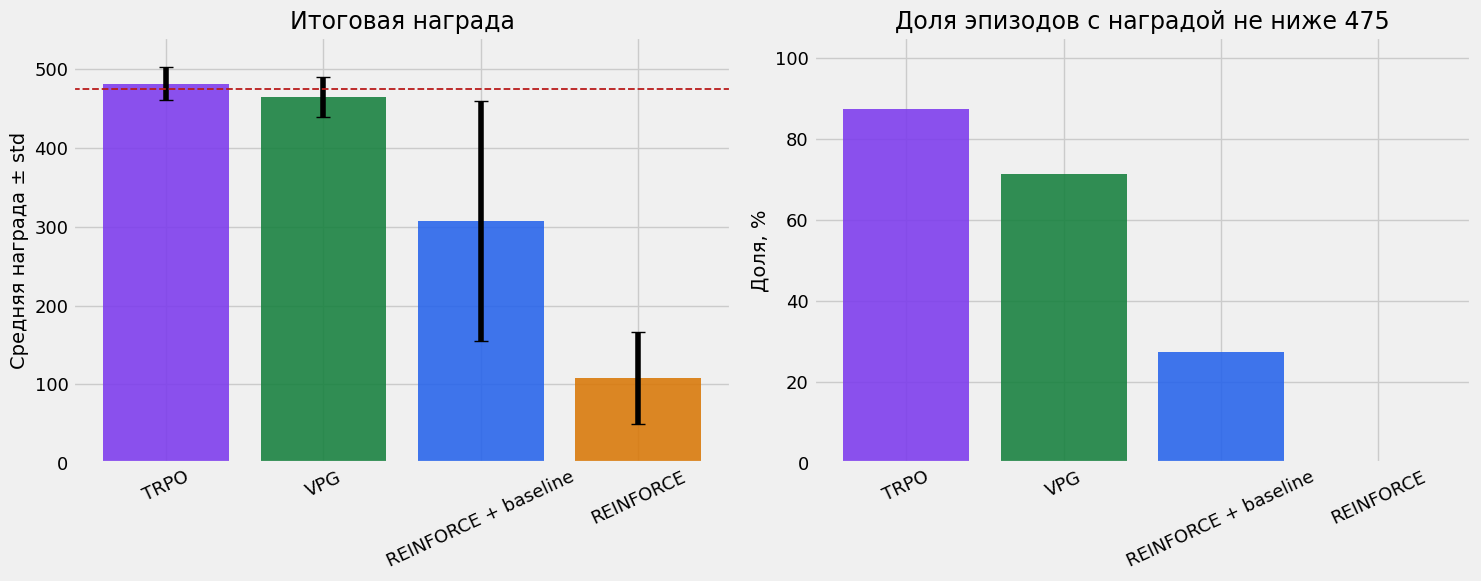

In [5]:
methods = list(summary["Метод"])
means = [float(summary.loc[summary["Метод"] == m, "Средняя награда"].iloc[0]) for m in methods]
stds = [float(summary.loc[summary["Метод"] == m, "Стандартное отклонение"].iloc[0]) for m in methods]
success = [float(summary.loc[summary["Метод"] == m, "Доля успешных эпизодов"].iloc[0]) * 100 for m in methods]
method_colors = [colors[m] for m in methods]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].bar(methods, means, yerr=stds, color=method_colors, alpha=0.88, capsize=5)
axes[0].axhline(475, color="#b91c1c", linestyle="--", linewidth=1.3)
axes[0].set_title("Итоговая награда")
axes[0].set_ylabel("Средняя награда ± std")
axes[0].tick_params(axis="x", rotation=25)
axes[0].set_ylim(0, 540)
axes[1].bar(methods, success, color=method_colors, alpha=0.88)
axes[1].set_title("Доля эпизодов с наградой не ниже 475")
axes[1].set_ylabel("Доля, %")
axes[1].tick_params(axis="x", rotation=25)
axes[1].set_ylim(0, 105)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "final_comparison.png", dpi=220)
plt.show()

## 6. Обсуждение 1 — адаптация REINFORCE

Выбрана среда `CartPole-v1`, поскольку пространство действий дискретное, а наблюдение имеет фиксированный размер четыре. Состояние подаётся в полносвязную сеть, на выходе находятся два логита. Из логитов строится распределение `Categorical`, поэтому агент сохраняет исследование и может выбирать оба действия. После окончания эпизода вычисляются $G_t$, затем Adam изменяет параметры политики по сумме $-\log\pi(a_t\mid s_t)G_t$.

Вопрос о сборщике траекторий решён непосредственно в функции `collect_episode`: она сохраняет состояния, действия, логарифмы вероятностей, энтропии и награды до терминального состояния. Такой сборщик подходит всем четырём вариантам и не смешивает данные соседних эпизодов.

## 7. Обсуждение 2 — инженерная базовая линия

При близком бюджете чистый REINFORCE получил 108.3 ± 58.2, а REINFORCE с базовой линией — 307.2 ± 152.7. Доля успешных оценочных эпизодов изменилась с 0.0% до 27.3%.

В реализации базовая линия равна среднему возврату по текущей траектории: $b=\frac{1}{T}\sum_tG_t$. В градиент попадает $G_t-b$: веса возвратов выше и ниже среднего получают разные знаки. Это среднее вычисляется из той же траектории, поэтому стандартное утверждение о несмещённости для базовой линии, независимой от текущего действия, нельзя автоматически перенести на эту оценку. Разброс между запусками остаётся заметным.

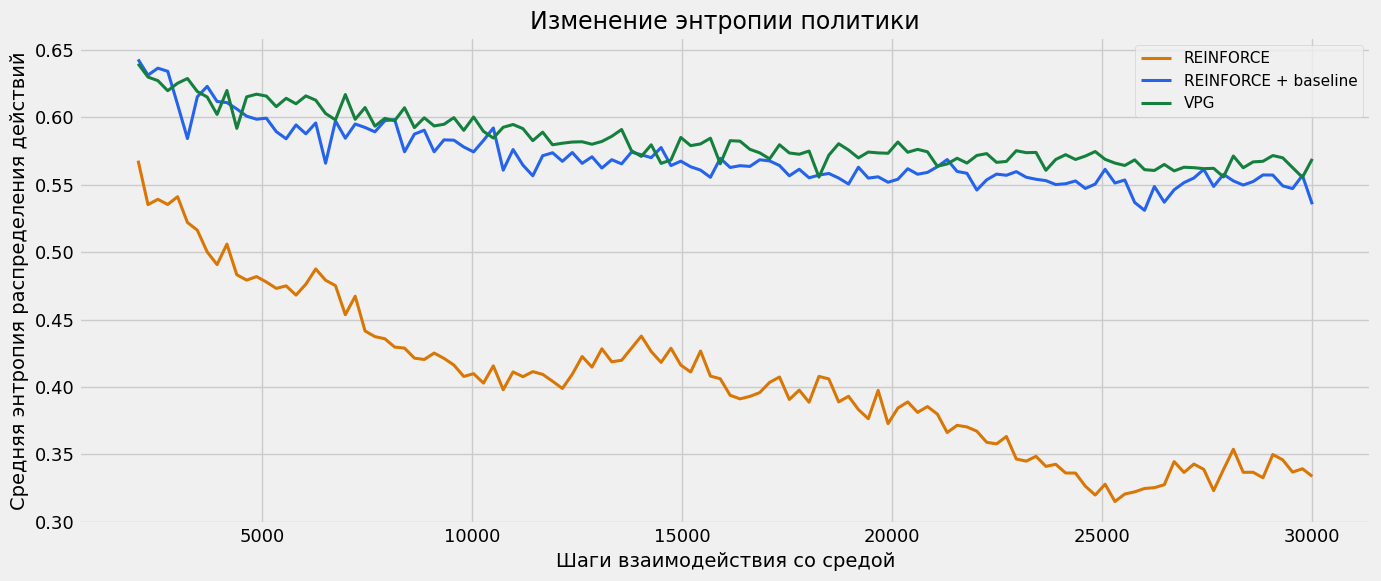

In [6]:
fig, ax = plt.subplots(figsize=(14, 6))
for method, color in [("REINFORCE", colors["REINFORCE"]), ("REINFORCE + baseline", colors["REINFORCE + baseline"]), ("VPG", colors["VPG"])]:
    matrices = []
    for run in results[method].values():
        x = np.asarray(run["train_steps"], dtype=float)
        y = np.asarray(run["entropy"], dtype=float)
        matrices.append(np.interp(grid, x, y))
    matrix = np.asarray(matrices)
    ax.plot(grid, matrix.mean(axis=0), color=color, linewidth=2.2, label=method)
ax.set_title("Изменение энтропии политики")
ax.set_xlabel("Шаги взаимодействия со средой")
ax.set_ylabel("Средняя энтропия распределения действий")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "policy_entropy.png", dpi=220)
plt.show()

## 8. Обсуждение 3 — VPG

В VPG базовая линия обучается сетью `ValueNet`. Для каждого состояния сеть даёт $V_\phi(s)$, а политика использует преимущество $A_t=G_t-V_\phi(s_t)$. Критик минимизирует MSE между $V_\phi(s_t)$ и возвратом, актор максимизирует взвешенную логарифмическую вероятность и получает бонус $0,01H(\pi)$.

Средняя итоговая награда VPG равна 464.2 ± 24.9, доля эпизодов с наградой не ниже 475 — 71.3%. Она выше результата варианта с инженерной базовой линией. Кроме обучаемой оценки здесь изменены нормализация преимущества, коэффициент обучения и энтропийный бонус, поэтому этот опыт не выделяет вклад каждого изменения по отдельности.

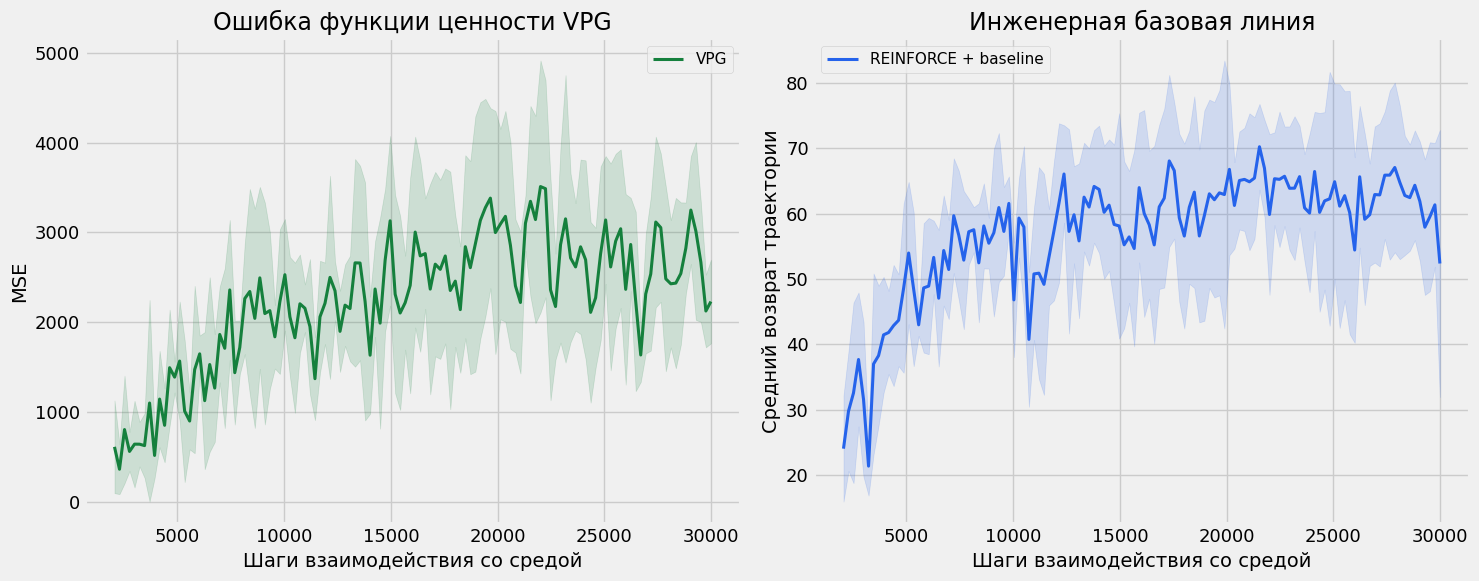

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for method, color, key, title in [
    ("VPG", colors["VPG"], "value_loss", "Ошибка функции ценности VPG"),
    ("REINFORCE + baseline", colors["REINFORCE + baseline"], "baseline", "Инженерная базовая линия"),
]:
    curves = []
    for run in results[method].values():
        x = np.asarray(run["train_steps"], dtype=float)
        y = np.asarray(run[key], dtype=float)
        curves.append(np.interp(grid, x, y))
    matrix = np.asarray(curves)
    ax = axes[0] if key == "value_loss" else axes[1]
    ax.plot(grid, matrix.mean(axis=0), color=color, linewidth=2.2, label=method)
    ax.fill_between(grid, np.maximum(0, matrix.mean(axis=0) - matrix.std(axis=0)), matrix.mean(axis=0) + matrix.std(axis=0), color=color, alpha=0.16)
    ax.set_title(title)
    ax.set_xlabel("Шаги взаимодействия со средой")
    ax.legend()
axes[0].set_ylabel("MSE")
axes[1].set_ylabel("Средний возврат траектории")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "baseline_diagnostics.png", dpi=220)
plt.show()

## 9. Обсуждение 4 — TRPO

В TRPO пакет набирается из полных эпизодов. Для каждой записи сохраняются старая вероятность действия и старая политика. Направление градиента суррогатной цели умножается на приближённую обратную матрицу Фишера методом сопряжённых градиентов. Затем линейный поиск принимает первый шаг, который увеличивает цель и сохраняет среднее KL не выше $\delta=0,01$.

TRPO получил 481.3 ± 20.6, а доля эпизодов с наградой не ниже 475 составила 87.3%. В этой серии средняя оценка TRPO выше VPG (464.2). Пять зерен и одна среда ограничивают обобщение; размер обновления при этом контролируется явно, как показано на графике KL.

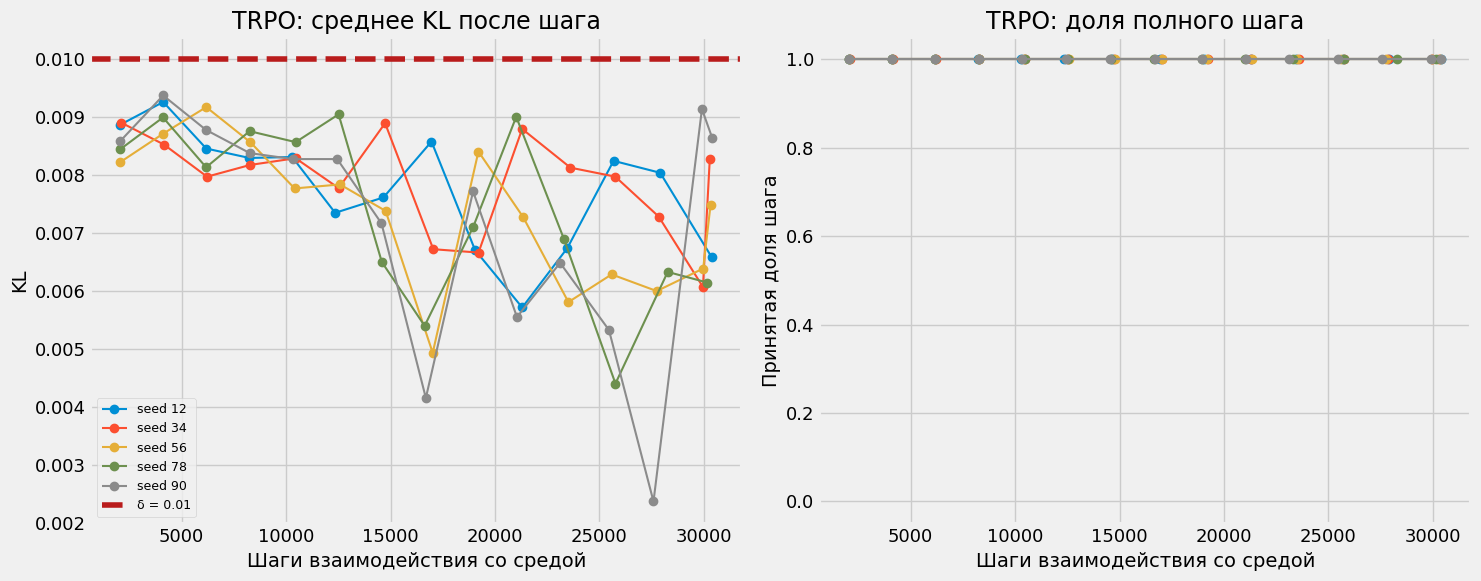

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for seed, run in results["TRPO"].items():
    axes[0].plot(run["train_steps"], run["kl"], marker="o", linewidth=1.5, label=f"seed {seed}")
    axes[1].plot(run["train_steps"], run["accepted_fraction"], marker="o", linewidth=1.5, label=f"seed {seed}")
axes[0].axhline(0.01, color="#b91c1c", linestyle="--", label="δ = 0.01")
axes[0].set_title("TRPO: среднее KL после шага")
axes[0].set_xlabel("Шаги взаимодействия со средой")
axes[0].set_ylabel("KL")
axes[1].set_title("TRPO: доля полного шага")
axes[1].set_xlabel("Шаги взаимодействия со средой")
axes[1].set_ylabel("Принятая доля шага")
axes[1].set_ylim(-0.05, 1.05)
axes[0].legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "trpo_diagnostics.png", dpi=220)
plt.show()

## 10. Итоговый вывод

    Все четыре алгоритма реализованы и проверены на одной среде, с одинаковой архитектурой политики, пятью зернами и общей процедурой оценки. Чистый REINFORCE получил наименьшую среднюю награду. Инженерная базовая линия повысила результат, но разброс между зернами остался большим. VPG и TRPO показали более высокие оценки; в этой серии наибольшую среднюю награду получил TRPO, который удерживает обновления в доверительной области.

Полученные различия относятся к заданной среде, архитектуре, бюджету и зернам. Для более сильного вывода потребуются дополнительные среды и увеличение числа шагов, но внутри поставленной лабораторной задачи сравнение проведено при одинаковых условиях.

In [9]:
# Финальная проверка чисел и наличия построенных материалов.
assert set(results) == {"REINFORCE", "REINFORCE + baseline", "VPG", "TRPO"}
for method, runs in results.items():
    assert len(runs) == 5
    assert all(np.isfinite(run["final_score"]) for run in runs.values())
    assert all(np.isfinite(run["final_success"]) for run in runs.values())
expected_figures = [
    "learning_curves.png",
    "final_comparison.png",
    "policy_entropy.png",
    "baseline_diagnostics.png",
    "trpo_diagnostics.png",
]
assert all((FIGURES_DIR / name).exists() for name in expected_figures)
print("Проверка пройдена: 4 метода, 5 зерен на метод, 5 графиков сохранены.")

Проверка пройдена: 4 метода, 5 зерен на метод, 5 графиков сохранены.


## 11. Воспроизведение

Для повторного запуска нужны Python 3.12, `numpy`, `pandas`, `matplotlib`, `torch` и `gymnasium`. В проекте сохранены `lab4_experiment.py`, `results/metrics.json` и пять PNG-графиков. Чтобы пересчитать метрики, в ячейке контрольного запуска установите `RUN_EXPERIMENTS = True`; для обычного просмотра оставьте `False`.